---
title: "Лекція 5. Динаміка мереж і багатомасштабне моделювання складних систем"
description: "Математичне моделювання складних систем | PhD F3 «Комп'ютерні науки» | КрНУ ім. М. Остроградського"
author: "&copy; [Valeriy Sydorenko](https://www.linkedin.com/in/valeriy-sydorenko-6782279a/), 2026"
date: today
jupyter: python3
bibliography: mmss-references.bib

format:
  html:
    code-fold: show
    code-summary: "Показати код"
    code-overflow: wrap
    toc: true
    toc-depth: 4
    toc-location: right
    number-sections: false
    embed-resources: true
    smooth-scroll: true
---

::: callout-note
## Примітка

Лекція охоплює:

- другу частину *Теми 6. Динаміка процесів у складних мережах (Dynamics on Complex Networks)* -- 1 год;
- *Тему 7. Багаторівневі, багатомасштабні та гібридні моделі* -- 1 год.

Наскрізна логіка:

$$
\text{local interaction}
\rightarrow
\text{collective dynamics}
\rightarrow
\text{stability / robustness / resilience}
\rightarrow
\text{multiple scales}
\rightarrow
\text{coupled / hybrid model}.
$$
:::

# Вступ

У Лекції 4 ми сформулювали загальну network dynamics model

$$
\mathbf{x}(t+1)
=
\mathbf{F}
\left(
\mathbf{x}(t),A,\Theta
\right)
$$

і показали, що однакове local rule на різних topology може породжувати різну macro-dynamics [@newman2018].

ЛР4 зробила наступний крок:

$$
\text{Network Model Specification v0.3}
\rightarrow
\text{Network Dynamics Specification v0.4}.
$$

Тепер маємо відповісти на два складніші питання.

1. Які *якісно різні* колективні режими можуть виникати на мережі?
2. Що робити, коли одного рівня або одного математичного формалізму недостатньо для опису системи?

Ці питання природно з'єднують network dynamics із multilevel, multiscale та hybrid modelling.

# Тема 6. Динаміка процесів у складних мережах (Dynamics on Complex Networks)

## 1. Від spreading до класів мережевої динаміки

У попередній лекції ми розглянули SI-подібний spreading process. Але dynamics on networks значно ширша.

Типові класи:

- diffusion;
- spreading;
- cascades;
- threshold dynamics;
- synchronization;
- consensus;
- failure propagation.

У загальному випадку

$$
\text{macro behavior}
=
\mathcal{D}
\left(
G,
F,
\Theta,
\mathbf{x}(0)
\right).
$$

Тобто collective regime визначається не topology окремо і не local rule окремо, а їх взаємодією [@newman2018; @newmanBarabasiWatts2006].

## 2. Diffusion і spreading -- не те саме

Для continuous quantity природною є diffusion model

$$
\frac{d\mathbf{x}}{dt}
=
-\kappa L\mathbf{x},
$$

де

$$
L=D-A
$$

-- graph Laplacian.

Тут величина перерозподіляється між nodes.

Для spreading process state часто є discrete:

$$
x_i(t)\in\{0,1\},
$$

а evolution визначається probabilistic або deterministic transition rule.

Отже,

$$
\text{diffusion}
\neq
\text{state spreading}.
$$

Обидва процеси залежать від topology, але мають різну математичну семантику.

## 3. Каскад (cascade)

*Каскад (cascade)* -- послідовність локальних state changes, яка через interactions може породити system-level transition.

Схематично:

$$
\text{local perturbation}
\rightarrow
\text{neighbor response}
\rightarrow
\text{secondary response}
\rightarrow
\cdots
\rightarrow
\text{macroscopic cascade}.
$$

Приклади:

- information adoption;
- failure propagation;
- load redistribution;
- behavioral adoption;
- activation of dependent services.

Важливо:

> велика cascade не обов'язково потребує великого initial perturbation.

## 4. Порогова модель (threshold model)

Нехай

$$
x_i(t)\in\{0,1\}
$$

і вузол активується, якщо частка active neighbors перевищує threshold $\phi_i$:

$$
x_i(t+1)
=
\begin{cases}
1,
&
\displaystyle
\frac{1}{k_i}
\sum_j a_{ij}x_j(t)
\ge
\phi_i,
\\
x_i(t),
&
\text{інакше}.
\end{cases}
$$

Це deterministic local rule.

Але system-level outcome може бути highly nonlinear:

$$
\text{small seed}
\rightarrow
\begin{cases}
\text{dies out},\\
\text{local cascade},\\
\text{global cascade}.
\end{cases}
$$

## 5. Ручний приклад threshold dynamics

Нехай вузол $i$ має чотирьох сусідів:

$$
k_i=4,
$$

а threshold

$$
\phi_i=0.5.
$$

Якщо активний один сусід:

$$
\frac{1}{4}=0.25<0.5,
$$

вузол не активується.

Якщо активні два:

$$
\frac{2}{4}=0.5\ge0.5,
$$

вузол активується.

Отже, одна додаткова локальна зміна може перевести вузол через threshold.

Саме такі nonlinear switching mechanisms можуть породжувати cascade behavior.

## 6. Topology і cascade condition

У threshold model degree має подвійний ефект.

Для fixed fractional threshold $\phi$ вузол з великим $k_i$:

- має більше potential sources of activation;
- але може потребувати більшої абсолютної кількості active neighbors.

Тому висновок

> «high-degree nodes завжди легше активувати»

не є загальним.

Потрібно враховувати одночасно

$$
k_i,
\quad
\phi_i,
\quad
\text{local neighborhood state}.
$$

## 7. Простий computational example

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

G = nx.watts_strogatz_graph(
    n=30,
    k=4,
    p=0.10,
    seed=42
)

def threshold_process(
    G,
    initial_active,
    phi=0.35,
    steps=15
):
    state = {
        node: int(node in initial_active)
        for node in G.nodes()
    }

    prevalence = [
        np.mean(list(state.values()))
    ]

    for _ in range(steps):
        new_state = state.copy()

        for node in G.nodes():
            if state[node] == 1:
                continue

            neighbors = list(
                G.neighbors(node)
            )

            active_fraction = np.mean([
                state[nbr]
                for nbr in neighbors
            ])

            if active_fraction >= phi:
                new_state[node] = 1

        state = new_state
        prevalence.append(
            np.mean(list(state.values()))
        )

    return np.asarray(prevalence)

Порівняємо кілька seed sizes за однакового $G$ та $\phi$.

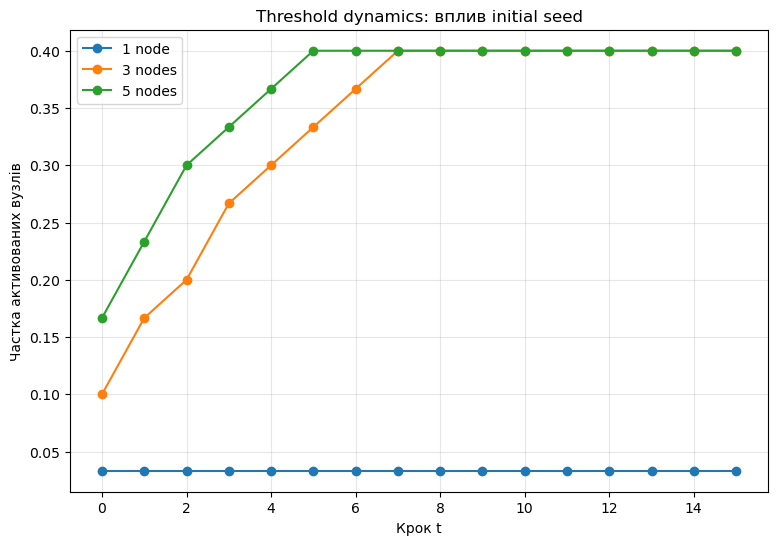

In [2]:
seed_sets = {
    "1 node": {0},
    "3 nodes": {0, 1, 2},
    "5 nodes": {0, 1, 2, 3, 4}
}

plt.figure(figsize=(9, 6))

for label, initial_active in seed_sets.items():
    trajectory = threshold_process(
        G,
        initial_active=initial_active,
        phi=0.35,
        steps=15
    )

    plt.plot(
        range(len(trajectory)),
        trajectory,
        marker="o",
        label=label
    )

plt.xlabel("Крок t")
plt.ylabel("Частка активованих вузлів")
plt.title("Threshold dynamics: вплив initial seed")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Цей experiment не доводить універсальної cascade threshold. Він лише показує, що

$$
\text{initial condition}
+
\text{topology}
+
\text{threshold rule}
$$

можуть створювати якісно різні outcomes.

## 8. Синхронізація (synchronization)

Інший клас dynamics виникає, коли nodes мають власну фазу або oscillatory state.

Класичний приклад -- networked Kuramoto model:

$$
\frac{d\theta_i}{dt}
=
\omega_i
+
K
\sum_j
a_{ij}
\sin(\theta_j-\theta_i),
$$

де:

- $\theta_i(t)$ -- phase вузла;
- $\omega_i$ -- natural frequency;
- $K$ -- coupling strength;
- $A$ -- network topology.

За слабкого coupling nodes поводяться відносно незалежно.

За достатнього coupling може виникнути collective synchronization [@newman2018].

## 9. Параметр порядку (order parameter)

Ступінь phase coherence можна описати complex order parameter:

$$
r(t)e^{i\psi(t)}
=
\frac{1}{N}
\sum_{j=1}^{N}
e^{i\theta_j(t)}.
$$

Тоді

$$
0\le r(t)\le1.
$$

Інтуїтивно:

- $r\approx0$ -- phases розподілені неузгоджено;
- $r\approx1$ -- phases майже синхронізовані.

Таким чином microstates

$$
\theta_1,\ldots,\theta_N
$$

породжують macro-observable

$$
r(t).
$$

Це ще один приклад emergence.

## 10. Stability, robustness і resilience -- різні поняття

Ці терміни часто змішують, але для моделювання їх потрібно розділяти.

### Стійкість (stability)

Питання:

> Що відбувається з trajectory після малої perturbation поблизу певного state або regime?

Наприклад, для equilibrium $x^*$:

$$
x(0)=x^*+\varepsilon.
$$

Чи повернеться система до $x^*$?

### Робастність (robustness)

Питання:

> Наскільки system function зберігається за structural або parametric perturbations?

Наприклад:

$$
G
\rightarrow
G-\Delta E.
$$

### Резильєнтність (resilience)

Питання:

> Чи здатна система після суттєвого disturbance відновити функцію або перейти до прийнятного regime?

Отже:

$$
\boxed{
\text{stability}
\neq
\text{robustness}
\neq
\text{resilience}
}
$$

## 11. Простий приклад robustness

Нехай функціональність network визначаємо як частку nodes у giant connected component:

$$
R(f)
=
\frac{|GCC(f)|}{N},
$$

де $f$ -- частка вилучених nodes.

Порівняємо:

- random failure;
- targeted removal high-degree nodes.

Це вже не просто structural statistic, а *response of network function to perturbation*.

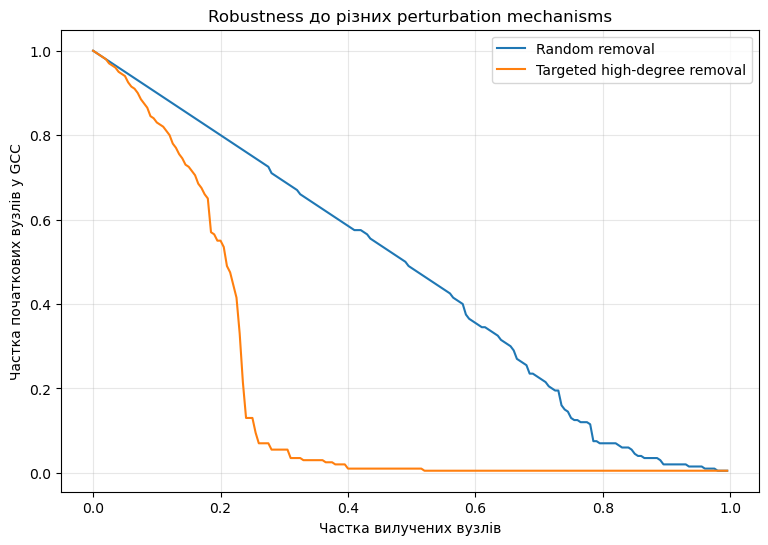

In [3]:
def gcc_fraction(G):
    if G.number_of_nodes() == 0:
        return 0.0

    gcc = max(
        nx.connected_components(G),
        key=len
    )

    return len(gcc) / G.number_of_nodes()

G0 = nx.barabasi_albert_graph(
    n=200,
    m=3,
    seed=42
)

def removal_curve(
    G,
    strategy="random",
    seed=42
):
    rng = np.random.default_rng(seed)
    H = G.copy()
    N0 = G.number_of_nodes()

    fractions_removed = [0.0]
    gcc_relative = [1.0]

    while H.number_of_nodes() > 1:
        if strategy == "random":
            node = rng.choice(
                list(H.nodes())
            )
        else:
            node = max(
                H.degree(),
                key=lambda x: x[1]
            )[0]

        H.remove_node(node)

        removed = (
            N0 - H.number_of_nodes()
        ) / N0

        if H.number_of_nodes() > 0:
            gcc = max(
                nx.connected_components(H),
                key=len
            )
            relative = len(gcc) / N0
        else:
            relative = 0.0

        fractions_removed.append(removed)
        gcc_relative.append(relative)

    return (
        np.asarray(fractions_removed),
        np.asarray(gcc_relative)
    )

f_random, r_random = removal_curve(
    G0,
    "random",
    seed=42
)

f_target, r_target = removal_curve(
    G0,
    "targeted",
    seed=42
)

plt.figure(figsize=(9, 6))
plt.plot(
    f_random,
    r_random,
    label="Random removal"
)
plt.plot(
    f_target,
    r_target,
    label="Targeted high-degree removal"
)
plt.xlabel("Частка вилучених вузлів")
plt.ylabel("Частка початкових вузлів у GCC")
plt.title("Robustness до різних perturbation mechanisms")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 12. Що показує robustness experiment

Ми змінили не лише *кількість* вилучених nodes, а mechanism of perturbation.

Тому

$$
\text{robustness}
=
R(
\text{system},
\text{function},
\text{perturbation class}
).
$$

Не існує meaningful твердження

> «мережа є робастною»

без уточнення:

- до чого;
- за якою function;
- у якому perturbation range.

Так само resilience потребує explicit recovery mechanism і time-dependent recovery criterion.

## 13. Завершення Теми 6

Можемо узагальнити:

$$
\boxed{
\text{Topology}
+
\text{Local dynamics}
+
\text{Parameters}
+
\text{Initial conditions}
+
\text{Perturbations}
\rightarrow
\text{Collective behavior}
}
$$

Network dynamics охоплює не лише spreading.

Вона включає:

- transitions;
- cascades;
- synchronization;
- failure propagation;
- recovery;
- regime changes.

Наступне питання виникає природно:

> Чи достатньо одного network-level description, якщо система одночасно має процеси на різних просторових, часових та організаційних масштабах?

# Тема 7. Багаторівневі, багатомасштабні та гібридні моделі

## 14. Чому одного рівня моделі недостатньо

Складна система часто має одночасно:

- individual components;
- groups / subsystems;
- global system state.

Схематично:

$$
\text{micro}
\rightarrow
\text{meso}
\rightarrow
\text{macro}.
$$

Але arrows працюють у двох напрямах:

$$
\text{micro}
\rightleftarrows
\text{meso}
\rightleftarrows
\text{macro}.
$$

Micro-interactions породжують macro-patterns, а macro-constraints можуть змінювати local behavior [@sayama2015; @radhakrishnan2021].

## 15. Багаторівнева модель (multilevel model)

*Рівень (level)* -- спосіб організації system description.

Наприклад:

### Micro-level
окремі users / agents:

$$
x_i(t).
$$

### Meso-level
communities:

$$
X_c(t)
=
\frac{1}{|C_c|}
\sum_{i\in C_c}x_i(t).
$$

### Macro-level
глобальна частка active nodes:

$$
\rho(t)
=
\frac{1}{N}
\sum_i x_i(t).
$$

Це три representations однієї системи, але вони відповідають на різні research questions.

## 16. Aggregation і information loss

Нехай microstate

$$
\mathbf{x}
=
(x_1,\ldots,x_N).
$$

Aggregation operator

$$
\mathcal{A}:
\mathbf{x}
\mapsto
X
$$

будує macrostate:

$$
X=\mathcal{A}(\mathbf{x}).
$$

Але загалом

$$
\mathcal{A}^{-1}(X)
$$

не є однозначним.

Багато різних microstates можуть давати однаковий macrostate.

Отже:

$$
\text{aggregation}
\Rightarrow
\text{information loss}.
$$

Це фундаментальна причина, чому macro-model не завжди може відтворити micro-mechanism.

## 17. Простий приклад

Для чотирьох binary agents:

$$
\mathbf{x}^{(1)}
=
(1,1,0,0),
$$

$$
\mathbf{x}^{(2)}
=
(1,0,1,0).
$$

В обох випадках

$$
\rho
=
\frac{1}{4}\sum_i x_i
=
0.5.
$$

Але якщо network topology різна, наступний стан може бути різним.

Тобто

$$
\rho(t)
$$

може бути недостатньою state variable для closed macro-dynamics.

Це приводить до *проблеми замикання (closure problem)*.

## 18. Проблема замикання (closure problem)

Хотілося б записати macro-model:

$$
X(t+1)=F(X(t)).
$$

Але якщо evolution залежить від hidden microstructure $Z(t)$, фактично:

$$
X(t+1)
=
F(X(t),Z(t)).
$$

Якщо $Z$ не можна виразити через $X$, macro-model не є closed.

Тоді можливі стратегії:

1. додати додаткові state variables;
2. побудувати closure approximation;
3. зберегти coupling із micro-model;
4. перейти до data-driven closure.

Саме тут multiscale і hybrid modelling стають не «додатковою складністю», а способом зробити модель адекватною research question [@radhakrishnan2021].

## 19. Багатомасштабна модель (multiscale model)

*Масштаб (scale)* може стосуватися:

- часу;
- простору;
- кількості components;
- resolution;
- characteristic process rate.

Наприклад:

$$
\tau_{fast}
\ll
\tau_{slow}.
$$

Якщо fast process релаксує за секунди, а slow process змінюється за години, використання одного time step для всього може бути computationally inefficient або numerically problematic.

## 20. Level і scale -- не синоніми

*Level* відповідає на питання:

> На якому рівні організації описується система?

*Scale*:

> Який characteristic resolution або rate має процес?

Наприклад, community -- meso-level object, але всередині нього можуть існувати fast і slow processes.

Тому

$$
\text{multilevel}
\neq
\text{multiscale}.
$$

У реальній моделі вони часто поєднуються.

## 21. Coupling між моделями

Нехай маємо дві підмоделі:

$$
\frac{dx}{dt}
=
f(x,y),
$$

$$
\frac{dy}{dt}
=
g(y,x).
$$

Тут $x$ і $y$ можуть представляти:

- різні scales;
- різні subsystems;
- різні mathematical formalisms.

Coupling означає, що output однієї моделі входить до іншої.

Схематично:

$$
M_1
\xrightarrow{y_{12}}
M_2,
\qquad
M_2
\xrightarrow{y_{21}}
M_1.
$$

## 22. Односторонній і двосторонній coupling

### One-way coupling

$$
M_1\rightarrow M_2.
$$

Перша model впливає на другу, але feedback відсутній.

### Two-way coupling

$$
M_1\rightleftarrows M_2.
$$

Models взаємно впливають одна на одну.

Two-way coupling часто краще відповідає complex adaptive systems, але створює додаткові питання:

- synchronization;
- numerical stability;
- data exchange;
- consistency;
- error propagation.

## 23. Гібридна модель (hybrid model)

У цій темі *гібридність (hybridity)* означає поєднання різних mathematical / computational representations в одній model architecture.

Наприклад:

$$
\text{ODE}
+
\text{discrete events},
$$

або

$$
\text{agent-based model}
+
\text{network model},
$$

або

$$
\text{physics-based model}
+
\text{data-driven component}.
$$

Останній тип детальніше розглядатимемо в Темі 12 [@bruntonKutz2022].

## 24. Discrete--continuous hybrid model

Нехай continuous state

$$
x(t)
$$

еволюціонує за ODE:

$$
\frac{dx}{dt}
=
f_q(x),
$$

де

$$
q\in\{1,\ldots,K\}
$$

-- discrete mode.

Коли event condition

$$
h(x)=0
$$

виконується, mode змінюється:

$$
q^-
\rightarrow
q^+.
$$

Тобто continuous trajectory залежить від discrete regime, а discrete transition -- від continuous state.

## 25. Простий приклад hybrid dynamics

Нехай

$$
x(t)
$$

-- system load.

У normal mode:

$$
\frac{dx}{dt}
=
a-bx.
$$

Якщо

$$
x(t)\ge x_{crit},
$$

система переходить у protection mode:

$$
\frac{dx}{dt}
=
a-cx,
\qquad
c>b.
$$

Маємо:

$$
\text{continuous state}
+
\text{discrete switching rule}.
$$

Окрема ODE без mode variable не описує всю логіку системи.

## 26. Co-simulation

Іноді підмоделі неможливо або недоцільно об'єднати в одну систему equations.

Тоді вони виконуються окремими solvers і періодично обмінюються даними:

$$
M_1(t_k)
\rightarrow
M_2(t_k),
$$

$$
M_2(t_k)
\rightarrow
M_1(t_{k+1}).
$$

Це *спільне моделювання (co-simulation)*.

Типова схема:

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {'fontSize':'18px','fontFamily':'Trebuchet MS, Verdana, Arial, sans-serif','primaryColor':'#E8F3FF','primaryBorderColor':'#3478A8','secondaryColor':'#FFF0C9','tertiaryColor':'#E7F6EC','lineColor':'#536878'}}}%%
flowchart LR
 A("Model A<br/>solver") --> C("Coupling /<br/>exchange")
 C --> B("Model B<br/>solver")
 B --> C
 C --> T("Synchronization<br/>at t_k")
```

## 27. Co-simulation породжує нові джерела похибки

Навіть якщо кожна submodel окремо verified, coupled model може мати нові errors:

- interpolation error;
- extrapolation error;
- synchronization error;
- time-step mismatch;
- interface inconsistency;
- feedback amplification.

Тому

$$
\text{verified }M_1
+
\text{verified }M_2
\not\Rightarrow
\text{verified coupled model}.
$$

Цей принцип безпосередньо підводить нас до майбутньої Теми 9 -- Verification & Validation [@oberkampfRoy2010].

## 28. Як вибрати рівень деталізації

Найдетальніша model не є автоматично найкращою.

Потрібно зіставити:

$$
\text{model resolution}
\leftrightarrow
\text{research question}.
$$

Надто coarse model може втратити mechanism.

Надто detailed model може створити:

- parameter explosion;
- identifiability problems;
- computational cost;
- validation problems;
- unnecessary uncertainty.

Тому level і scale -- це *modeling decisions*, а не властивості, які потрібно максимізувати.

## 29. Принцип мінімально достатньої моделі

Для заданого Research Question модель повинна бути настільки складною, наскільки потрібно для відтворення mechanism і quantities of interest, але не складнішою без наукової причини.

Схематично:

$$
\boxed{
\text{RQ}
\rightarrow
\text{required mechanisms}
\rightarrow
\text{required levels/scales}
\rightarrow
\text{model architecture}
}
$$

Це не заклик до oversimplification.

Це вимога, щоб кожний додатковий level, scale або coupling мав дослідницьке обґрунтування.

## 30. Приклад архітектури для складної інформаційної системи

Розглянемо умовну online system.

### Micro-level

Users / agents:

$$
x_i(t).
$$

### Network level

Interactions:

$$
G(t)=(V,E(t)).
$$

### Meso-level

Communities:

$$
C_1(t),\ldots,C_K(t).
$$

### Macro-level

Global activity:

$$
\rho(t).
$$

### External level

Platform policy або exogenous events:

$$
u(t).
$$

Тоді system model може мати вигляд

$$
\mathbf{x}(t+1)
=
F(
\mathbf{x}(t),
A(t),
u(t)
),
$$

$$
A(t+1)
=
H(
A(t),
\mathbf{x}(t)
).
$$

Маємо feedback:

$$
\text{behavior}
\rightleftarrows
\text{network structure}.
$$

## 31. Adaptive network як міст між Темами 6 і 7

У Лекції 4 topology була fixed:

$$
A=\text{const}.
$$

У складній adaptive system:

$$
A=A(t).
$$

І не лише states залежать від network:

$$
\mathbf{x}(t+1)
=
F(\mathbf{x}(t),A(t)),
$$

але й network змінюється під впливом states:

$$
A(t+1)
=
H(A(t),\mathbf{x}(t)).
$$

Це вже coupled multilevel dynamics.

Саме тут межа між «process on network» та «evolving network» стає принципово важливою.

## 32. Модельна архітектура як об'єкт дослідження

Для PhD-рівня недостатньо написати:

> «використаємо hybrid model».

Потрібно специфікувати:

1. які submodels існують;
2. які state variables має кожна;
3. які scales вони представляють;
4. які inputs/outputs передаються;
5. у якому напрямі йде coupling;
6. з якою frequency відбувається exchange;
7. які assumptions робляться на interfaces;
8. які нові errors створює coupling.

Отже, model architecture сама стає частиною наукового обґрунтування.

## 33. Матриця вибору представлення

| Дослідницька потреба | Доцільне представлення |
|---|---|
| локальні interactions | agent/network model |
| aggregate dynamics | ODE / difference equations |
| кілька organizational levels | multilevel model |
| різні characteristic times | multiscale model |
| continuous + event logic | discrete--continuous hybrid |
| різні спеціалізовані solvers | co-simulation |
| mechanism + learned correction | knowledge-driven + data-driven hybrid |

Це не жорстка класифікація. Одна research model може одночасно належати до кількох рядків.

## 34. Що буде далі

Після перших п'яти лекцій ми вже побудували логіку:

$$
\text{complex system}
\rightarrow
\text{formalization}
\rightarrow
\text{nonlinear / stochastic dynamics}
\rightarrow
\text{network structure}
\rightarrow
\text{network dynamics}
\rightarrow
\text{multilevel / multiscale / hybrid architecture}.
$$

Наступний блок курсу змінює питання.

Ми вже маємо model architecture.

Тепер потрібно встановити:

> *Як визначити її параметри за даними і наскільки можна довіряти отриманій моделі?*

Тому Лекція 6:

$$
\text{identification / calibration}
\rightarrow
\text{Verification \& Validation}.
$$

# 35. Зв'язок із наступними лабораторними роботами

ЛР4 завершила network-dynamics block:

$$
\text{Network Dynamics Specification v0.4}.
$$

Наступна лабораторна робота має нормативну назву:

*«Лабораторна робота 5. Ідентифікація та калібрування математичної моделі за даними».*

Тому multilevel/hybrid material цієї лекції виконує дві функції:

1. завершує архітектурний блок курсу;
2. показує, що parameter identification залежить від того, *яку саме model architecture* ми обрали.

Чим складніша coupled model, тим гострішими стають питання:

$$
\text{identifiability},
\quad
\text{calibration},
\quad
\text{validation}.
$$

# 36. Підсумкова схема

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {'fontSize':'18px','fontFamily':'Trebuchet MS, Verdana, Arial, sans-serif','primaryColor':'#E8F3FF','primaryBorderColor':'#3478A8','secondaryColor':'#FFF0C9','tertiaryColor':'#E7F6EC','lineColor':'#536878'}}}%%
flowchart LR
 A("Network<br/>structure") --> B("Local<br/>dynamics")
 B --> C("Collective<br/>regimes")
 C --> D("Stability / Robustness /<br/>Resilience")
 D --> E("Multiple levels<br/>and scales")
 E --> F("Coupled<br/>models")
 F --> G("Hybrid /<br/>co-simulation")
 G --> H("Identification<br/>and V&V")
```

# Контрольні запитання

1. Чим diffusion відрізняється від state spreading?
2. Що називають cascade?
3. Як формулюється fractional threshold rule?
4. Чому однаковий threshold може мати різний ефект для nodes різного degree?
5. Як initial seed впливає на cascade?
6. Що описує Kuramoto model?
7. Що означає order parameter $r(t)$?
8. Чим stability відрізняється від robustness?
9. Чим resilience відрізняється від stability?
10. Чому robustness потрібно визначати відносно perturbation class?
11. Що таке micro-, meso- і macro-level?
12. Чому aggregation призводить до information loss?
13. Що таке closure problem?
14. Які існують способи подолання closure problem?
15. Що називають scale?
16. Чим level відрізняється від scale?
17. Що таке one-way coupling?
18. Що таке two-way coupling?
19. Що означає hybrid model у контексті цієї теми?
20. Як працює discrete--continuous hybrid model?
21. Що таке co-simulation?
22. Які додаткові errors породжує coupling?
23. Чому verified submodels не гарантують verified coupled model?
24. Чому найдетальніша model не обов'язково найкраща?
25. Що означає принцип мінімально достатньої моделі?
26. Що таке adaptive network?
27. Чим process on network відрізняється від evolving network?
28. Які елементи потрібно специфікувати для hybrid architecture?
29. Як model architecture пов'язана з identifiability?
30. Чому наступним природним кроком є identification і V&V?

# Висновки

1. Dynamics on networks включає diffusion, spreading, cascades, threshold processes, synchronization та failure/recovery processes.
2. Collective outcome визначається взаємодією topology, local dynamics, parameters та initial conditions.
3. Threshold dynamics показує, як local nonlinear switching може породити macroscopic cascade.
4. Synchronization демонструє emergence macro-order із взаємодії oscillatory nodes.
5. Stability, robustness і resilience описують різні властивості моделі та не повинні використовуватися як синоніми.
6. Складні системи часто потребують одночасного опису micro-, meso- та macro-level.
7. Aggregation неминуче втрачає частину micro-information і може породжувати closure problem.
8. Multiscale modelling потрібне, коли процеси мають різні characteristic scales.
9. Multilevel і multiscale -- пов'язані, але не тотожні поняття.
10. Hybrid model поєднує різні mathematical або computational representations.
11. Co-simulation дозволяє поєднати окремі solvers, але створює нові interface і synchronization errors.
12. Model resolution повинна визначатися Research Question, а не прагненням максимізувати деталізацію.
13. Adaptive network демонструє двосторонній coupling між system states і structure.
14. Після вибору model architecture наступним завданням стає identification, calibration та оцінювання credibility моделі.

# Джерела та корисні ресурси

Використовується спільна накопичувальна бібліографічна база курсу `mmss-references.bib`.

- [Network Science -- Albert-László Barabási](https://networksciencebook.com/)
- [NetworkX documentation](https://networkx.org/documentation/stable/)
- [Introduction to the Modeling and Analysis of Complex Systems -- Hiroki Sayama](https://milneopentextbooks.org/introduction-to-the-modeling-and-analysis-of-complex-systems/)
- [SciPy documentation](https://docs.scipy.org/doc/scipy/)
- [NumPy documentation](https://numpy.org/doc/stable/)
- [Matplotlib documentation](https://matplotlib.org/stable/)

# References